In [1]:
import pandas as pd
import numpy as np
import datetime as dt
import re

import matplotlib.pyplot as plt
import plotly.express as px
from wordcloud import WordCloud, STOPWORDS

<h1>Climate Terms</h1>

<h2>The Guardian</h2>

In [2]:
guardian_df = pd.read_csv("data/02_pre-processed/guardian_2010_2025_climate_terms.csv")
guardian_df["date"] = pd.to_datetime(guardian_df["date"])
guardian_df.head()

,id,section_id,section_name,date,title,url,abstract,body
0,environment/2010/dec/30/humans-causing-global-...,environment,Environment,2010-12-30 09:00:00+00:00,Are humans definitely causing global warming?,https://www.theguardian.com/environment/2010/d...,The world's most respected scientific bodies h...,Just as the world's most respected scientific ...
1,environment/2010/dec/09/why-havent-governments...,environment,Environment,2010-12-14 12:00:01+00:00,If global warming was such a big deal wouldn't...,https://www.theguardian.com/environment/2010/d...,"Despite years of negotiations, world leaders h...","Most governments have – in theory, at least – ..."
2,environment/2010/dec/07/committee-on-climate-c...,environment,Environment,2010-12-07 06:00:02+00:00,Committee on Climate Change advises UK to cut ...,https://www.theguardian.com/environment/2010/d...,Britain is set world-leading carbon-emissions ...,The UK would cut its greenhouse gas emissions ...
3,environment/2010/dec/01/cancun-climate-change-...,environment,Environment,2010-12-01 16:31:49+00:00,Cancún climate change summit: China's journey ...,https://www.theguardian.com/environment/2010/d...,"Investment in green energy, efficient trains a...",As negotiators arrive in Cancun for the next r...
4,sustainable-business/blog/clean-technology-sol...,sustainable-business,Guardian Sustainable Business,2010-11-29 12:45:12+00:00,Clean technology solutions to global warming n...,https://www.theguardian.com/sustainable-busine...,Clare Brook: Only a clear regulatory framework...,Given all we know about the threat of climate ...


In [3]:
# top 10 sections
guardian_df["section_name"].value_counts().head(10)

section_name
Environment                      20505
Opinion                           7440
Australia news                    7424
World news                        5320
Business                          4720
US news                           4297
Guardian Sustainable Business     3105
Politics                          2767
UK news                           1533
Global development                1480
Name: count, dtype: int64

<h3>Word Cloud</h3>

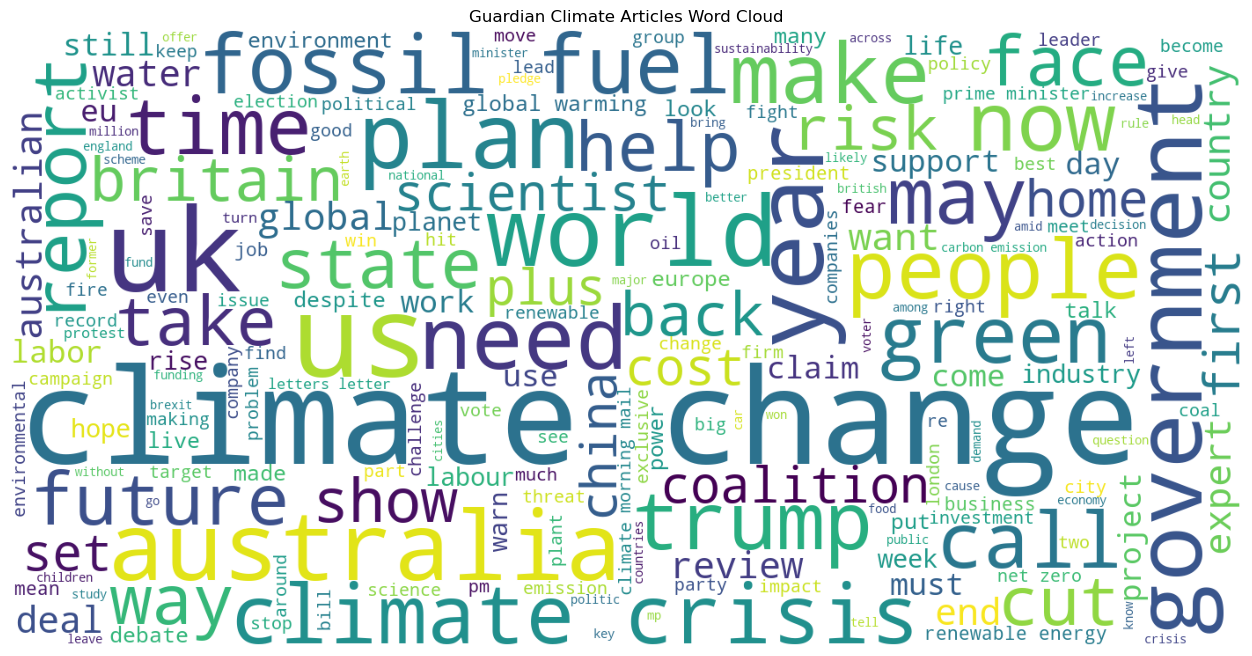

In [5]:
# Word Cloud

preprocessed_text = " ".join((guardian_df["title"] + " " + guardian_df["abstract"]).to_list())
preprocessed_text = preprocessed_text.lower() # lowercase
preprocessed_text = re.sub(r"[^\w\s]", " ", preprocessed_text) # remove punctuation aka anything that is not letters or whitespace
# remove stopwords using the built-in ones from wordcloud as well as some news specific ones for our use case
custom_stopwords = {"says", "say", "said", "would", "could", "also", "one", "new", "will"} # no stemming or lemmatization so we need exact matches, this visualization is not our focus
stopwords = STOPWORDS.union(custom_stopwords)

wordcloud = WordCloud(
    width=1400,
    height=700,
    background_color="white",
    stopwords=stopwords,
    min_word_length=2 # no single letters
).generate(preprocessed_text)

plt.figure(figsize=(16, 8))
plt.imshow(wordcloud)
plt.axis("off")
plt.title("Guardian Climate Articles Word Cloud")
plt.show()

<h3>Line Charts - Length</h3>

Mean no of articles per year: 4617.0625
Total no of articles: 73873


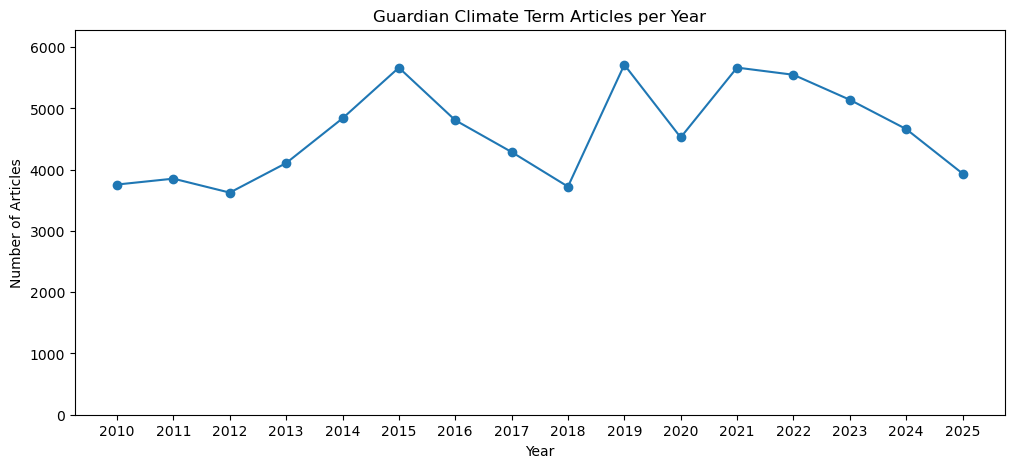

In [6]:
df_lengths = []
for year in range(2010, 2026):
    length = len(guardian_df[guardian_df["date"].dt.year == year])
    df_lengths.append(length)
    
print(f"Mean no of articles per year: {np.mean(df_lengths)}")
print(f"Total no of articles: {len(guardian_df)}")

plt.figure(figsize=(12, 5))
plt.plot(range(2010, 2026), df_lengths, marker="o")
plt.ylim(bottom=0, top=(np.max(df_lengths) + np.max(df_lengths)*0.1)) # set upper limit at 10% above max val
plt.xticks(range(2010, 2026))
plt.title("Guardian Climate Term Articles per Year")
plt.xlabel("Year")
plt.ylabel("Number of Articles")
plt.show()

In [7]:
df_lengths

[3758,
 3854,
 3626,
 4108,
 4838,
 5666,
 4808,
 4289,
 3724,
 5714,
 4527,
 5667,
 5550,
 5142,
 4664,
 3938]

<h2>NYT</h2>

In [8]:
nyt_df = pd.read_csv("data/02_pre-processed/nyt_2020_2025_climate_terms.csv")
nyt_df["date"] = pd.to_datetime(nyt_df["date"])
nyt_df.head()

,id,section_name,subsection_name,date,title,url,keywords,abstract
0,nyt://article/a2e65924-de68-5bed-b00e-4424c4f3...,Arts,,2020-01-30 23:12:57,Things to Do in N.Y.C. This February,https://www.nytimes.com/2020/01/30/arts/things...,New York City,"A month’s worth of free, family-friendly and o..."
1,nyt://article/54877656-88bd-5f19-9077-de839ac2...,Business,Economy,2020-01-30 20:02:34,"California, Mired in a Housing Crisis, Rejects...",https://www.nytimes.com/2020/01/30/business/ec...,"California, Real Estate and Housing (Residenti...",A lawmaker’s push for denser development near ...
2,nyt://article/329fe101-fb79-551c-8d34-fc608a0b...,Climate,,2020-01-30 14:11:27,Trump Administration Moves to Relax Rules Agai...,https://www.nytimes.com/2020/01/30/climate/tru...,"Birds, Animal Migration, Animal Abuse, Rights ...",A proposed regulation would codify a legal opi...
3,nyt://article/be382c87-a88a-5444-a61a-e63d7caf...,Business,Media,2020-01-30 13:39:50,‘Every Day Matters’: Guardian Stops Accepting ...,https://www.nytimes.com/2020/01/30/business/me...,"Newspapers, Guardian (British Newspaper), Adve...",It said the decision was based on the efforts ...
4,nyt://article/9b6fdfa3-6ee3-5ba3-bd62-ed21b0e9...,Business,DealBook,2020-01-30 12:11:30,Elon Musk Hits Back at Critics,https://www.nytimes.com/2020/01/30/business/de...,"Tesla Motors Inc, Musk, Elon",Tesla reported a $105 million quarterly profit...


In [9]:
# top 10 sections
nyt_df["section_name"].value_counts().head(10)

section_name
U.S.                    2263
Climate                 1974
Business                1935
Opinion                 1852
World                   1553
Briefing                1244
New York                 368
Arts                     357
Books                    267
The Learning Network     263
Name: count, dtype: int64

<h3>Word Cloud</h3>

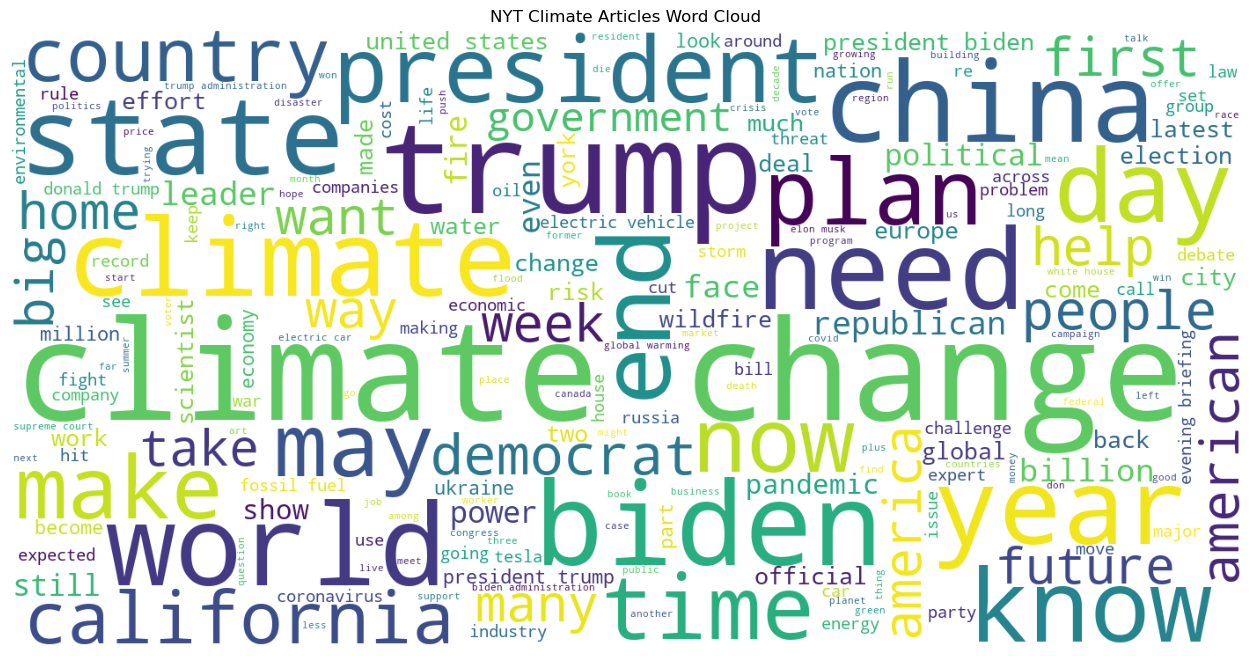

In [10]:
# Word Cloud

preprocessed_text = " ".join((nyt_df["title"] + " " + nyt_df["abstract"]).to_list())
preprocessed_text = preprocessed_text.lower() # lowercase
preprocessed_text = re.sub(r"[^\w\s]", " ", preprocessed_text) # remove punctuation aka anything that is not letters or whitespace
# remove stopwords using the built-in ones from wordcloud as well as some news specific ones for our use case
custom_stopwords = {"says", "say", "said", "would", "could", "also", "one", "new", "will"}
stopwords = STOPWORDS.union(custom_stopwords)

wordcloud = WordCloud(
    width=1400,
    height=700,
    background_color="white",
    stopwords=stopwords,
    min_word_length=2 # no single letters
).generate(preprocessed_text)

plt.figure(figsize=(16, 8))
plt.imshow(wordcloud)
plt.axis("off")
plt.title("NYT Climate Articles Word Cloud")
plt.show()

<h3>Line Charts - Length</h3>

Mean no of articles per year: 2326.3333333333335
Total no of articles: 13958


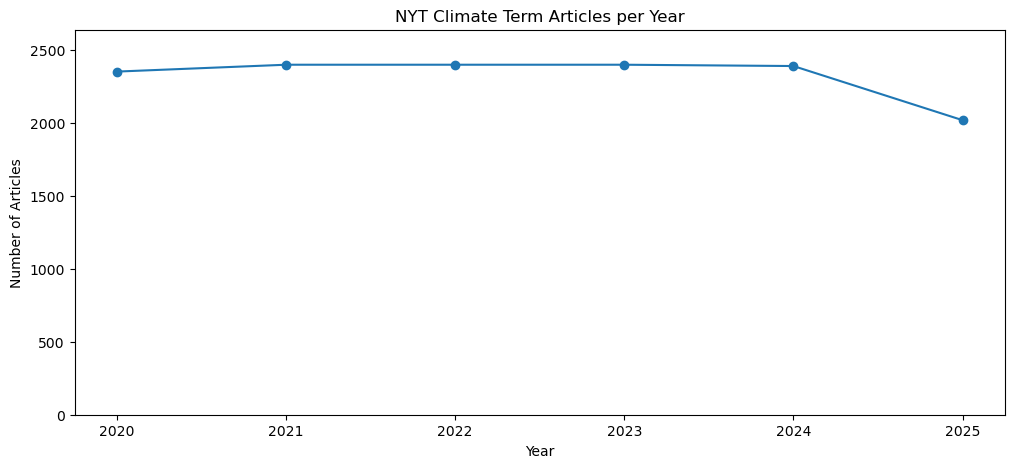

In [11]:
df_lengths = []
for year in range(2020, 2026):
    length = len(nyt_df[nyt_df["date"].dt.year == year])
    #print(len(nyt_df[nyt_df["date"].dt.year == year]))
    df_lengths.append(length)
    
print(f"Mean no of articles per year: {np.mean(df_lengths)}")
print(f"Total no of articles: {len(nyt_df)}")

plt.figure(figsize=(12, 5))
plt.plot(range(2020, 2026), df_lengths, marker="o")
plt.ylim(bottom=0, top=(np.max(df_lengths) + np.max(df_lengths)*0.1)) # set upper limit at 10% above max val
plt.xticks(range(2020, 2026))
plt.title("NYT Climate Term Articles per Year")
plt.xlabel("Year")
plt.ylabel("Number of Articles")
plt.show()

# we max out at our 2400 (200 articles per month) limit for most years

<h1>Climate Activists</h1>

<h2>The Guardian</h2>

In [12]:
guardian_act_df = pd.read_csv("data/02_pre-processed/guardian_2010_2026_climate_activists.csv")
guardian_act_df["date"] = pd.to_datetime(guardian_act_df["date"])
guardian_act_df.head()

,id,section_id,section_name,date,title,url,abstract,body
0,environment/2010/nov/25/copenhagen-climate-act...,environment,Environment,2010-11-25 13:47:47,Copenhagen climate activists found guilty,https://www.theguardian.com/environment/2010/n...,Two Danish protesters are found guilty of orga...,Two Danish activists who took part in the Cope...
1,leeds/2010/nov/09/climate-activists-meet-leeds...,leeds,Leeds,2010-11-09 10:38:59,Climate activists meet Leeds MP Fabian Hamilton,https://www.theguardian.com/leeds/2010/nov/09/...,Campaign for action on climate change leads to...,Leeds community activists campaigning for acti...
2,environment/2010/dec/16/danish-police-proteste...,environment,Environment,2010-12-16 15:42:37,Danish police ordered to compensate climate pr...,https://www.theguardian.com/environment/2010/d...,"In an unprecedented ruling, a Danish judge has...",Danish police have been ordered to pay tens of...
3,music/2010/nov/23/radiohead-thom-yorke-sculpture,music,Music,2010-11-23 10:56:47,Radiohead fans: Thom Yorke needs you ... to fo...,https://www.theguardian.com/music/2010/nov/23/...,"Singer seeks 2,000 people to help build a livi...",Thom Yorke wants your help to recreate an 11th...
4,environment/blog/2010/oct/04/10-10-campaign-ev...,environment,Environment,2010-10-04 10:49:21,Activists across the globe prepare for day of ...,https://www.theguardian.com/environment/blog/2...,Juliette Jowit: This year's campaign promises ...,"Last year it was hailed as the ""most widesprea..."


<h3>Word Cloud</h3>

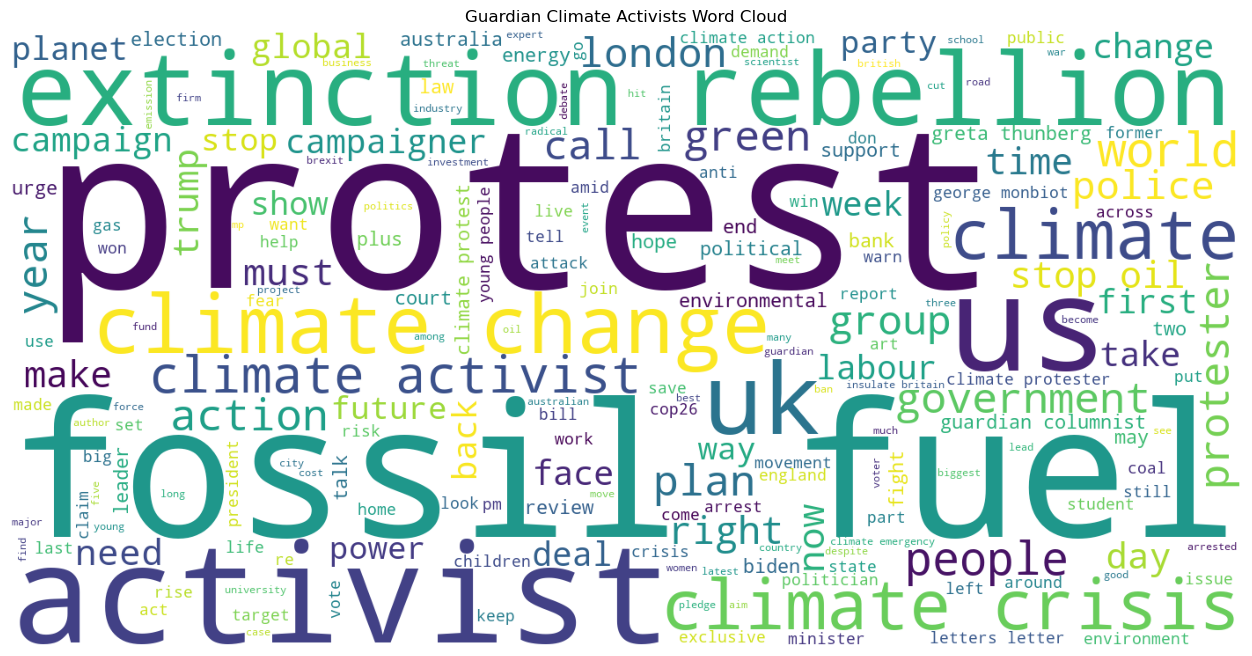

In [13]:
# Word Cloud

preprocessed_text = " ".join((guardian_act_df["title"] + " " + guardian_act_df["abstract"]).to_list())

preprocessed_text = preprocessed_text.lower() # lowercase
preprocessed_text = re.sub(r"[^\w\s]", " ", preprocessed_text) # remove punctuation aka anything that is not letters or whitespace
# remove stopwords using the built-in ones from wordcloud as well as some news specific ones for our use case
custom_stopwords = {"says", "say", "said", "would", "could", "also", "one", "new", "will"}
stopwords = STOPWORDS.union(custom_stopwords)

wordcloud = WordCloud(
    width=1400,
    height=700,
    background_color="white",
    stopwords=stopwords,
    min_word_length=2
).generate(preprocessed_text)

plt.figure(figsize=(16, 8))
plt.imshow(wordcloud)
plt.axis("off")
plt.title("Guardian Climate Activists Word Cloud")
plt.show()

<h3>Line Charts - Length</h3>

Mean no of articles per year: 293.25
Total no of articles: 4720


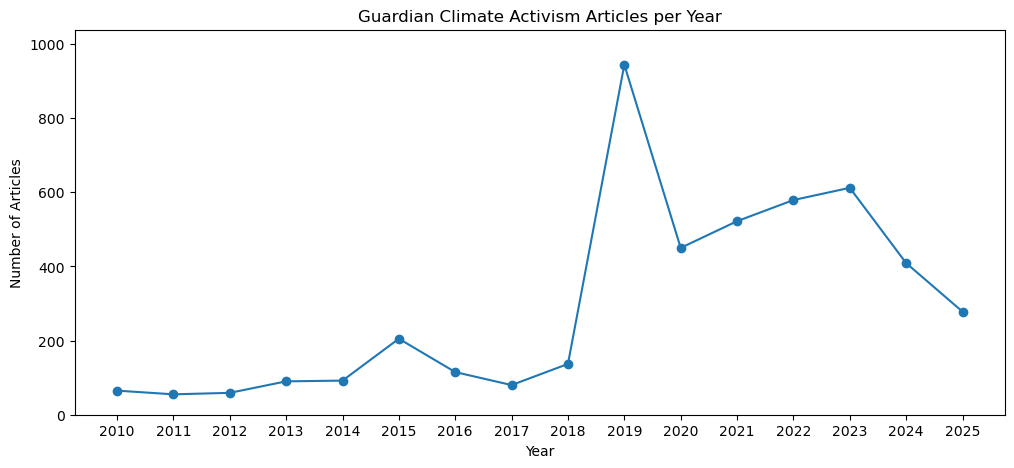

In [14]:
df_lengths = []
for year in range(2010, 2026):
    length = len(guardian_act_df[guardian_act_df["date"].dt.year == year])
    #print(len(guardian_df[guardian_df["date"].dt.year == year]))
    df_lengths.append(length)
    
print(f"Mean no of articles per year: {np.mean(df_lengths)}")
print(f"Total no of articles: {len(guardian_act_df)}")

plt.figure(figsize=(12, 5))
plt.plot(range(2010, 2026), df_lengths, marker="o")
plt.ylim(bottom=0, top=(np.max(df_lengths) + np.max(df_lengths)*0.1)) # set upper limit at 10% above max val
plt.xticks(range(2010, 2026))
plt.title("Guardian Climate Activism Articles per Year")
plt.xlabel("Year")
plt.ylabel("Number of Articles")
plt.show()

Mean no of articles per year: 491.375
Total no of articles: 4720


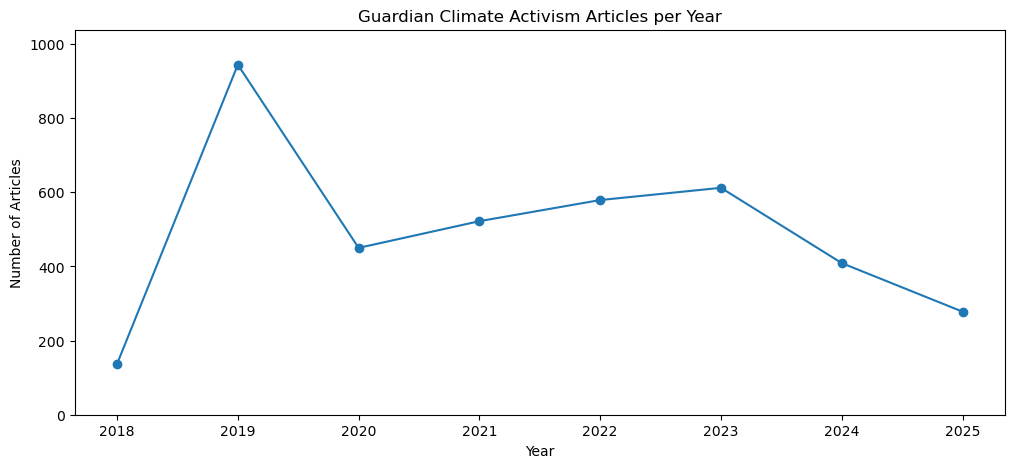

In [15]:
df_lengths = []
for year in range(2018, 2026):
    length = len(guardian_act_df[guardian_act_df["date"].dt.year == year])
    #print(len(guardian_df[guardian_df["date"].dt.year == year]))
    df_lengths.append(length)
    
print(f"Mean no of articles per year: {np.mean(df_lengths)}")
print(f"Total no of articles: {len(guardian_act_df)}")

plt.figure(figsize=(12, 5))
plt.plot(range(2018, 2026), df_lengths, marker="o")
plt.ylim(bottom=0, top=(np.max(df_lengths) + np.max(df_lengths)*0.1)) # set upper limit at 10% above max val
plt.xticks(range(2018, 2026))
plt.title("Guardian Climate Activism Articles per Year")
plt.xlabel("Year")
plt.ylabel("Number of Articles")
plt.show()

<h3>Pie & Bar Charts - Sections</h3>

'Top 10 sections:'

section_name
Environment       1496
Opinion            667
World news         398
US news            339
UK news            226
Australia news     222
Politics           192
Business           160
Books              101
Sport               96
Name: count, dtype: int64

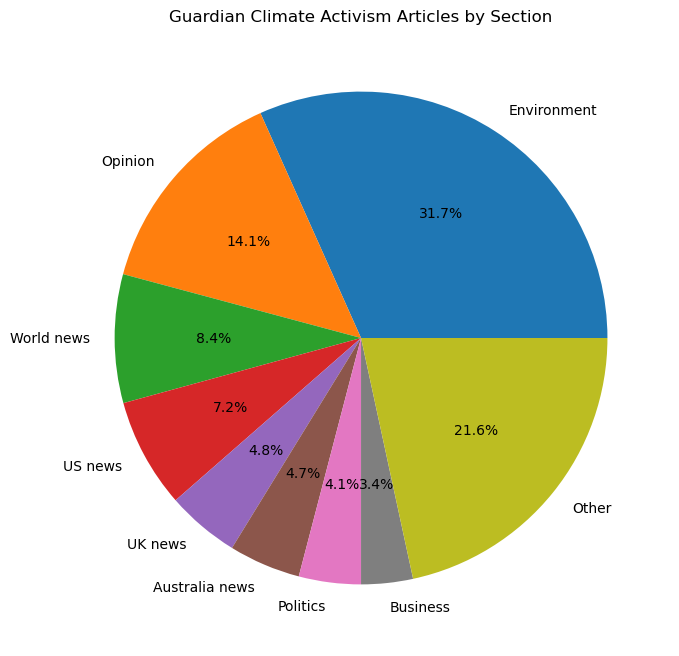

In [16]:
section_counts = guardian_act_df["section_name"].value_counts()
display(f"Top 10 sections:")
display(section_counts.head(10))

section_counts_adapted = section_counts.copy()
# group small sections into "Other" for readability
threshold = 0.03
small = section_counts[section_counts / len(guardian_act_df) < threshold]
large = section_counts[section_counts / len(guardian_act_df) >= threshold]

section_counts_adapted = large.copy()
section_counts_adapted["Other"] = small.sum()

plt.figure(figsize=(8, 8))
plt.pie(
    section_counts_adapted,
    labels=section_counts_adapted.index,
    autopct="%1.1f%%", # formatting into percentage with one decimal pt
)
plt.title("Guardian Climate Activism Articles by Section")
plt.show()

In [17]:
section_counts_by_year = guardian_act_df.pivot_table( # using a pivot table instead of group by to get the desired format of date as index and sections as columns
    index=guardian_act_df["date"].dt.year,
    columns="section_name",
    aggfunc="size", # count occurences
    fill_value=0 # if no articles in this section in a year
)
display(section_counts_by_year)

# group small sections into "Other" for readability
threshold = 0.01
section_totals = section_counts_by_year.sum()
total = section_totals.sum() # get total sum by first summing across columns (section names) and then across the resulting one as well
sections_below_threshold = section_totals[section_totals / total < threshold].index # find sections below the threshold when summing across years
section_counts_by_year["Other"] = section_counts_by_year[sections_below_threshold].sum(axis=1) # sum those up into the "Other" section on the row/year-wise
section_counts_by_year = section_counts_by_year.drop(columns=sections_below_threshold) # remove columns below threshold
section_counts_by_year

section_name,Animals farmed,Art and design,Australia news,Books,Business,Cities,Community,Culture,Culture professionals network,Dine: Hope Grows,...,Teacher Network,Technology,Television & radio,The Filter,Travel,UK news,US news,Wellness,Working in development,World news
date,,,,,,,,,,,,,,,,,,,,,
2010,0,0,0,2,1,0,0,1,0,0,...,0,2,0,0,1,0,0,0,0,2
2011,0,0,0,3,2,0,0,0,0,0,...,0,1,0,0,0,3,1,0,0,4
2012,0,0,0,2,0,0,0,0,1,0,...,1,2,0,0,0,1,2,0,0,4
2013,0,0,1,4,1,0,0,2,1,0,...,0,2,1,0,0,0,0,0,0,2
2014,0,0,2,3,3,0,0,0,0,0,...,0,0,0,0,0,1,0,0,5,7
2015,0,1,3,4,9,2,0,0,0,0,...,0,0,0,0,0,1,10,0,0,6
2016,0,4,6,2,4,0,0,0,0,0,...,0,0,0,0,0,0,19,0,1,1
2017,0,0,3,5,4,1,0,0,0,0,...,0,2,1,0,0,0,10,0,1,7
2018,1,2,6,2,7,0,1,1,0,0,...,0,1,0,0,0,6,9,0,0,9


section_name,Art and design,Australia news,Books,Business,Environment,Film,Life and style,Music,Opinion,Politics,Sport,Television & radio,UK news,US news,World news,Other
date,,,,,,,,,,,,,,,,
2010,0,0,2,1,28,0,2,2,6,5,3,0,0,0,2,14
2011,0,0,3,2,22,2,2,0,9,0,2,0,3,1,4,5
2012,0,0,2,0,18,1,1,3,9,0,0,0,1,2,4,18
2013,0,1,4,1,31,1,2,1,13,3,0,1,0,0,2,30
2014,0,2,3,3,32,0,0,1,15,2,0,0,1,0,7,26
2015,1,3,4,9,111,1,3,1,15,5,2,0,1,10,6,33
2016,4,6,2,4,46,1,2,1,16,1,2,0,0,19,1,10
2017,0,3,5,4,29,0,1,1,9,0,1,1,0,10,7,9
2018,2,6,2,7,51,1,2,1,21,0,1,0,6,9,9,19


<Axes: xlabel='date'>

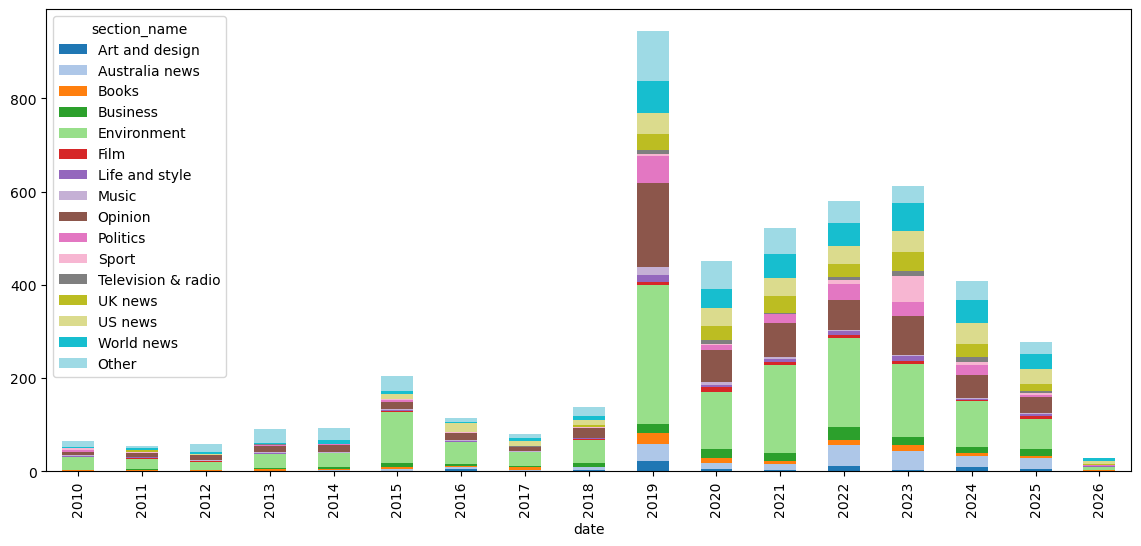

In [18]:
# stacked bar chart
section_counts_by_year.plot(kind="bar", stacked=True, figsize=(14, 6), colormap="tab20")

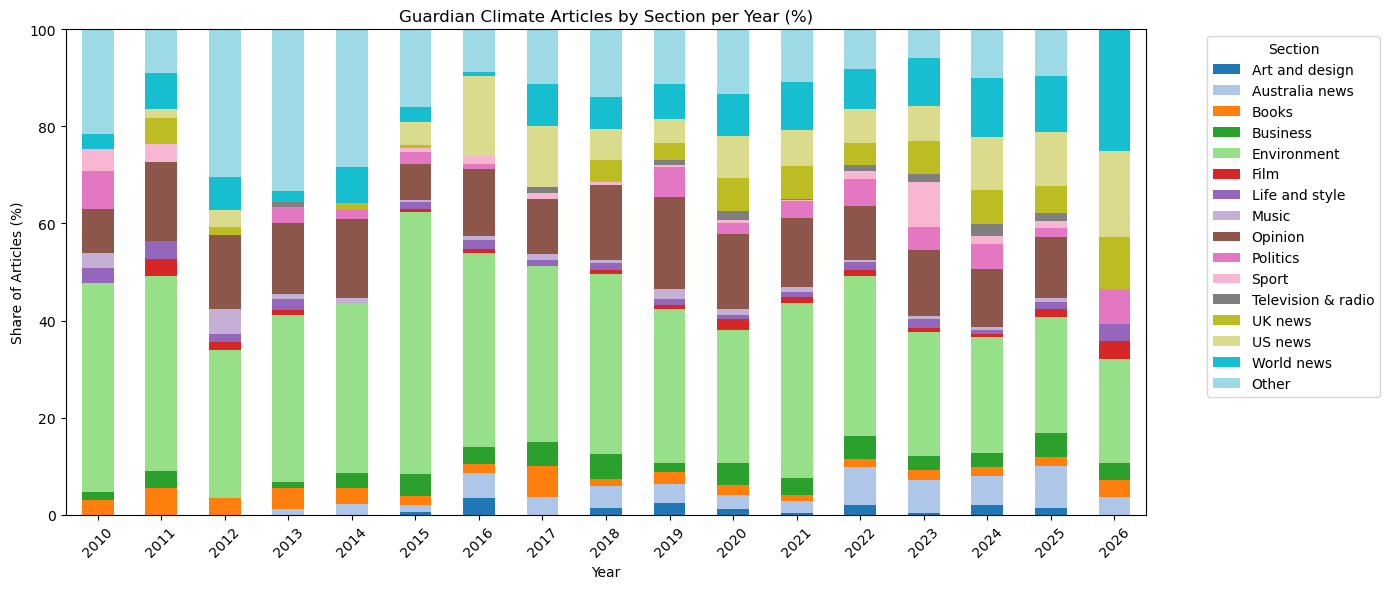

In [19]:
# same stacked bar chart but with relative frequencies per year

# calculate year- aka row-wise proportions using element-wise division by the sum of reach row
section_year_pct = section_counts_by_year.div(section_counts_by_year.sum(axis=1), axis=0) * 100

section_year_pct.plot(
    kind="bar",
    stacked=True,
    figsize=(14, 6),
    colormap="tab20",
)

plt.title("Guardian Climate Articles by Section per Year (%)")
plt.xlabel("Year")
plt.ylabel("Share of Articles (%)")
plt.xticks(rotation=45)
plt.ylim(0, 100)
plt.legend(title="Section", bbox_to_anchor=(1.05, 1), loc="upper left") # anchor the legend to the right outside the plot for readability
plt.tight_layout()
plt.show()

# distributions stay largely similar, no particularly interesting trends

<h2>NYT</h2>

In [20]:
nyt_act_df = pd.read_csv("data/02_pre-processed/nyt_2018_2025_climate_activists.csv")
nyt_act_df["date"] = pd.to_datetime(nyt_act_df["date"])
nyt_act_df.head()

,id,section_name,subsection_name,date,title,url,keywords,abstract
0,nyt://article/bdeb19ff-9c69-5335-a0fa-6a1b19a1...,Opinion,Sunday Opinion,2018-12-28 20:11:02,The Exhilaration of Revolt,https://www.nytimes.com/2018/12/28/opinion/tea...,"Demonstrations, Protests and Riots, Organized ...",Teachers who have taken their fight to the str...
1,nyt://article/b8b5b690-4f06-50ec-8df7-8e96fbc5...,Opinion,,2018-12-27 11:00:03,Forget the Carbon Tax for Now,https://www.nytimes.com/2018/12/27/opinion/car...,"Greenhouse Gas Emissions, Taxation, Carbon Cap...",It’s politically toxic. There are other ways t...
2,nyt://article/fb40326d-9188-5c27-ba72-0ea4a483...,Opinion,,2018-12-17 00:14:28,The Secret to Winning in 2020,https://www.nytimes.com/2018/12/16/opinion/dem...,"Presidential Election of 2020, United States P...","It’s the populism, stupid."
3,nyt://article/b127de54-9f30-57dd-a73c-ccc8e8e9...,U.S.,Politics,2018-12-07 00:38:33,Joe Manchin Faces Liberal Opposition in Bid to...,https://www.nytimes.com/2018/12/06/us/politics...,"United States Politics and Government, Electio...",The West Virginia senator’s support for coal h...
4,nyt://article/41b42eda-4436-53dd-bcd3-ce664973...,Opinion,,2018-12-06 11:00:05,France’s Combustible Climate Politics,https://www.nytimes.com/2018/12/06/opinion/fra...,"France, Yellow Vests Movement, Macron, Emmanue...",Climate policy should be about solving problem...


<h3>Word Cloud</h3>

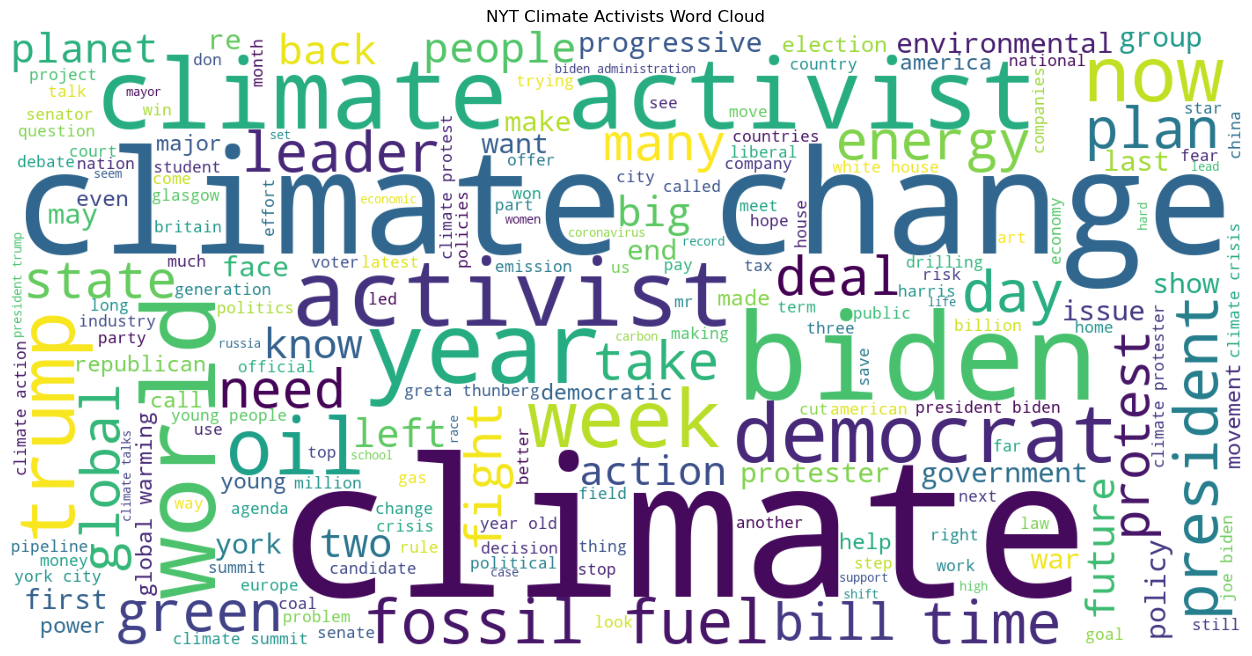

In [21]:
# Word Cloud

preprocessed_text = " ".join((nyt_act_df["title"] + " " + nyt_act_df["abstract"]).to_list())

preprocessed_text = preprocessed_text.lower() # lowercase
preprocessed_text = re.sub(r"[^\w\s]", " ", preprocessed_text) # remove punctuation aka anything that is not letters or whitespace
# remove stopwords using the built-in ones from wordcloud as well as some news specific ones for our use case
custom_stopwords = {"says", "say", "said", "would", "could", "also", "one", "new", "will"}
stopwords = STOPWORDS.union(custom_stopwords)

wordcloud = WordCloud(
    width=1400,
    height=700,
    background_color="white",
    stopwords=stopwords,
    min_word_length=2
).generate(preprocessed_text)

plt.figure(figsize=(16, 8))
plt.imshow(wordcloud)
plt.axis("off")
plt.title("NYT Climate Activists Word Cloud")
plt.show()

<h3>Line Charts - Length</h3>

Mean no of articles per year: 145.625
Total no of articles: 1165


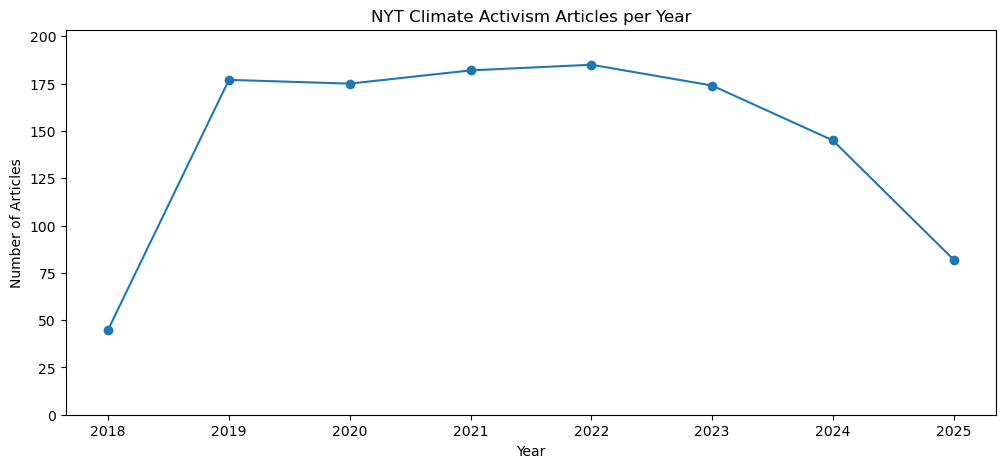

In [22]:
df_lengths = []
for year in range(2018, 2026):
    length = len(nyt_act_df[nyt_act_df["date"].dt.year == year])
    #print(len(nyt_df[nyt_df["date"].dt.year == year]))
    df_lengths.append(length)
    
print(f"Mean no of articles per year: {np.mean(df_lengths)}")
print(f"Total no of articles: {len(nyt_act_df)}")

plt.figure(figsize=(12, 5))
plt.plot(range(2018, 2026), df_lengths, marker="o")
plt.ylim(bottom=0, top=(np.max(df_lengths) + np.max(df_lengths)*0.1)) # set upper limit at 10% above max val
plt.xticks(range(2018, 2026))
plt.title("NYT Climate Activism Articles per Year")
plt.xlabel("Year")
plt.ylabel("Number of Articles")
plt.show()

<h3>Pie & Bar Charts - Sections</h3>

'Top 10 sections:'

section_name
Climate                 265
Opinion                 171
U.S.                    160
World                   147
Business                 90
Briefing                 66
Arts                     47
New York                 44
Podcasts                 23
The Learning Network     20
Name: count, dtype: int64

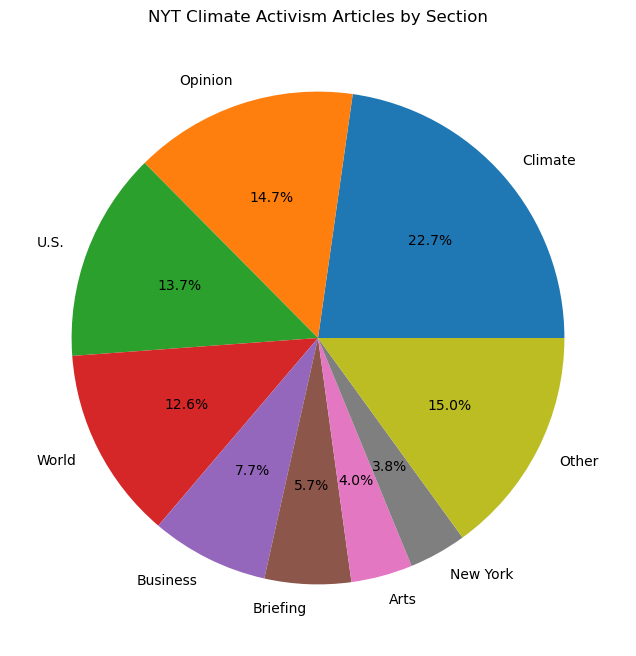

In [23]:
section_counts = nyt_act_df["section_name"].value_counts()
display(f"Top 10 sections:")
display(section_counts.head(10))

section_counts_adapted = section_counts.copy()
# group small sections into "Other" for readability
threshold = 0.03
section_counts_adapted["Other"] = section_counts_adapted[section_counts_adapted / len(nyt_act_df) < threshold].sum() # sum those below threshold into new col
section_counts_adapted = section_counts_adapted[section_counts_adapted / len(nyt_act_df) >= threshold] # filter out those below threshold

plt.figure(figsize=(8, 8))
plt.pie(
    section_counts_adapted,
    labels=section_counts_adapted.index,
    autopct="%1.1f%%", # formatting into percentage with one decimal pt
)
plt.title("NYT Climate Activism Articles by Section")
plt.show()

In [24]:
section_counts_by_year = nyt_act_df.pivot_table( # using a pivot table instead of group by to get the desired format of date as index and sections as columns
    index=nyt_act_df["date"].dt.year,
    columns="section_name",
    aggfunc="size", # count occurences
    fill_value=0 # if no articles in this section in a year
)
display(section_counts_by_year)

# group small sections into "Other" for readability
threshold = 0.01
section_totals = section_counts_by_year.sum()
total = section_totals.sum() # get total sum by first summing across columns (section names) and then across the resulting one as well
sections_below_threshold = section_totals[section_totals / total < threshold].index # find sections below the threshold when summing across years
section_counts_by_year["Other"] = section_counts_by_year[sections_below_threshold].sum(axis=1) # sum those up into the "Other" section on the row/year-wise
section_counts_by_year = section_counts_by_year.drop(columns=sections_below_threshold) # remove columns below threshold
section_counts_by_year

section_name,Arts,Books,Briefing,Business,Climate,Fashion,Food,Gameplay,Headway,Health,...,Technology,The Learning Network,The Upshot,The Weekly,Theater,Times Insider,Travel,U.S.,World,Your Money
date,,,,,,,,,,,,,,,,,,,,,
2018,1,0,0,0,1,4,0,0,0,0,...,0,3,1,0,0,0,1,4,7,0
2019,7,1,12,5,24,1,1,0,0,0,...,3,5,1,1,0,0,1,28,26,0
2020,3,3,3,10,25,0,0,1,0,0,...,3,0,2,0,1,0,1,69,15,1
2021,3,2,11,20,33,1,2,1,0,0,...,1,6,5,0,0,0,0,19,41,0
2022,8,2,18,12,57,0,0,0,0,1,...,0,3,0,0,1,1,0,14,20,0
2023,12,2,12,21,46,2,0,0,0,0,...,4,2,1,0,1,2,0,10,22,0
2024,8,1,5,13,54,0,0,0,1,0,...,1,1,0,0,2,0,1,13,11,0
2025,5,2,5,9,25,0,0,0,0,0,...,0,0,0,0,0,0,0,3,5,0


section_name,Arts,Books,Briefing,Business,Climate,Magazine,New York,Opinion,Podcasts,Sports,Style,Technology,The Learning Network,U.S.,World,Other
date,,,,,,,,,,,,,,,,
2018,1,0,0,0,1,2,1,15,0,2,1,0,3,4,7,8
2019,7,1,12,5,24,1,12,36,1,3,2,3,5,28,26,11
2020,3,3,3,10,25,1,3,23,0,0,6,3,0,69,15,11
2021,3,2,11,20,33,1,7,20,3,5,0,1,6,19,41,10
2022,8,2,18,12,57,2,4,26,12,0,1,0,3,14,20,6
2023,12,2,12,21,46,2,2,21,3,5,3,4,2,10,22,7
2024,8,1,5,13,54,2,8,18,3,0,1,1,1,13,11,6
2025,5,2,5,9,25,4,7,12,1,0,1,0,0,3,5,3


<Axes: xlabel='date'>

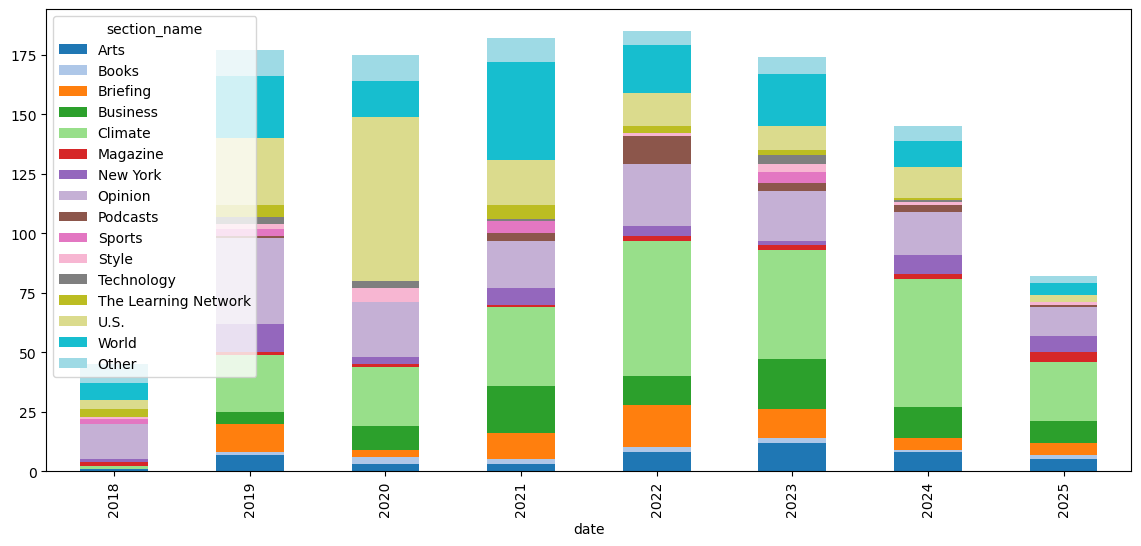

In [25]:
section_counts_by_year.plot(kind="bar", stacked=True, figsize=(14, 6), colormap="tab20")

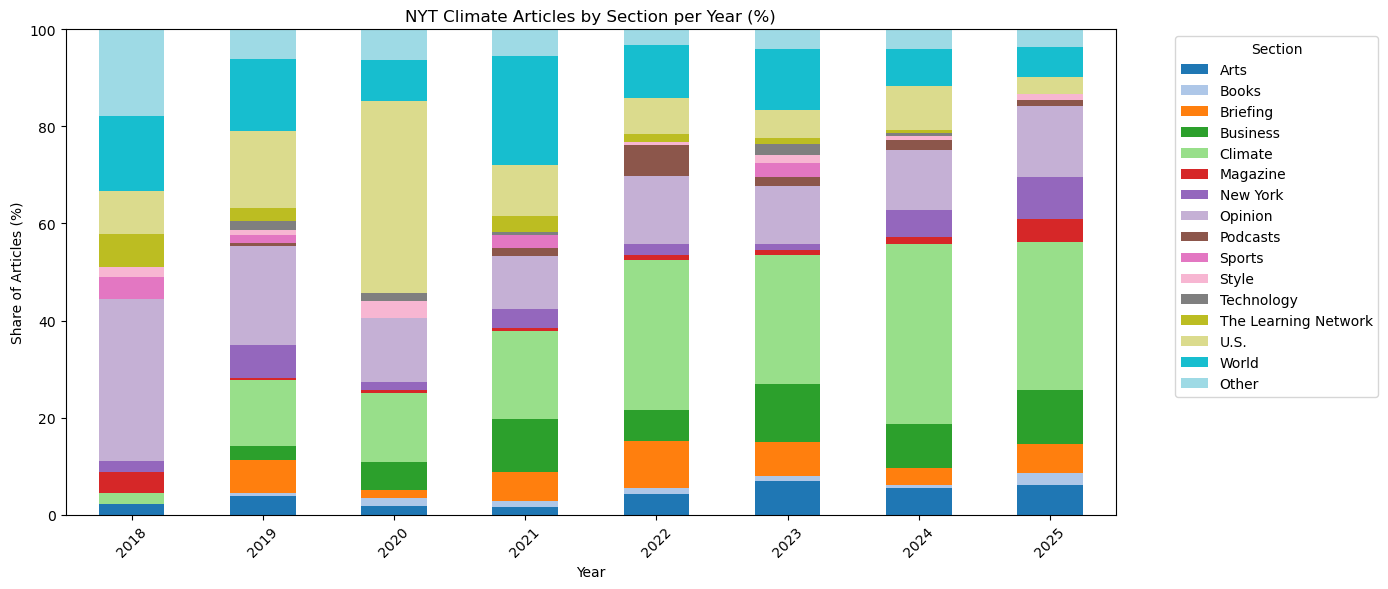

In [26]:
# same stacked bar chart but with relative frequencies per year

# calculate year- aka row-wise proportions using element-wise division by the sum of reach row
section_year_pct = section_counts_by_year.div(section_counts_by_year.sum(axis=1), axis=0) * 100

section_year_pct.plot(
    kind="bar",
    stacked=True,
    figsize=(14, 6),
    colormap="tab20",
)

plt.title("NYT Climate Articles by Section per Year (%)")
plt.xlabel("Year")
plt.ylabel("Share of Articles (%)")
plt.xticks(rotation=45)
plt.ylim(0, 100)
plt.legend(title="Section", bbox_to_anchor=(1.05, 1), loc="upper left")
plt.tight_layout()
plt.show()

# climate section increases initially then stays similar in size by 2022
# U.S. took up a lot in 2020 (COVID?)
# interestingly, the "world" section is similar in size to that of the guardian. ig international climate articles are more likely
# to be classified as "climate" rather than "world"